<p align='center'><img src='../assets/logo_team.png' width='140'></p>

<h1 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Exercice VII · Présence de sinistres extrêmes (garantie Vol)</h1>

On injecte deux sinistres Vol de 2 M€ et 3 M€ (positions 2344 et 100788 de la base), puis on découpe avec
**seed 2021** comme dans l'énoncé. Variables des modèles : Couverture, Qualite, Zonier_Vol.

> Remarque : le corrigé réutilise l'échantillon de seed 2016. Avec seed 2021, **aucun** des deux graves n'est dans la
> base d'apprentissage (ils sont tous les deux en base test) ; avec seed 2016, celui de 2 M€ est en apprentissage.
> On traite les deux cas, qui illustrent deux facettes du problème.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src import theme as T, graphiques as GR
from src.data import *
from src.indicateurs import *
from src import modeles as M
print("Rendu :", T.configurer_notebook())
pd.options.display.float_format = "{:,.4f}".format

from src.graves import mean_excess, ecreter, base_cout_ecretee, taux_surcharge, synthese_seuils

Rendu : plotly_mimetype+notebook_connected+png


In [2]:
bd = charger_base()
bd2 = injecter_graves(bd)
for seed in (2021, 2016):
    np.random.seed(seed); s = set(np.random.choice(len(bd), 300000, replace=False))
    print(f"seed {seed} : position 2344 en apprentissage = {2344 in s} · position 100788 = {100788 in s}")
bda, bdt, samp = decouper(bd2, seed=2021)
bdc = base_cout(bda, "Vol")

seed 2021 : position 2344 en apprentissage = False · position 100788 = False
seed 2016 : position 2344 en apprentissage = True · position 100788 = False


<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Question 1 · Évaluer la sinistralité extrême</h3>

count       11,412
mean         3,193
std         33,844
min              0
50%          2,450
99%         15,559
99.5%       22,666
99.9%       30,651
max      3,000,000
Name: Coût unitaire, dtype: str
Part de la charge Vol portée par les 2 sinistres injectés : 13.2%


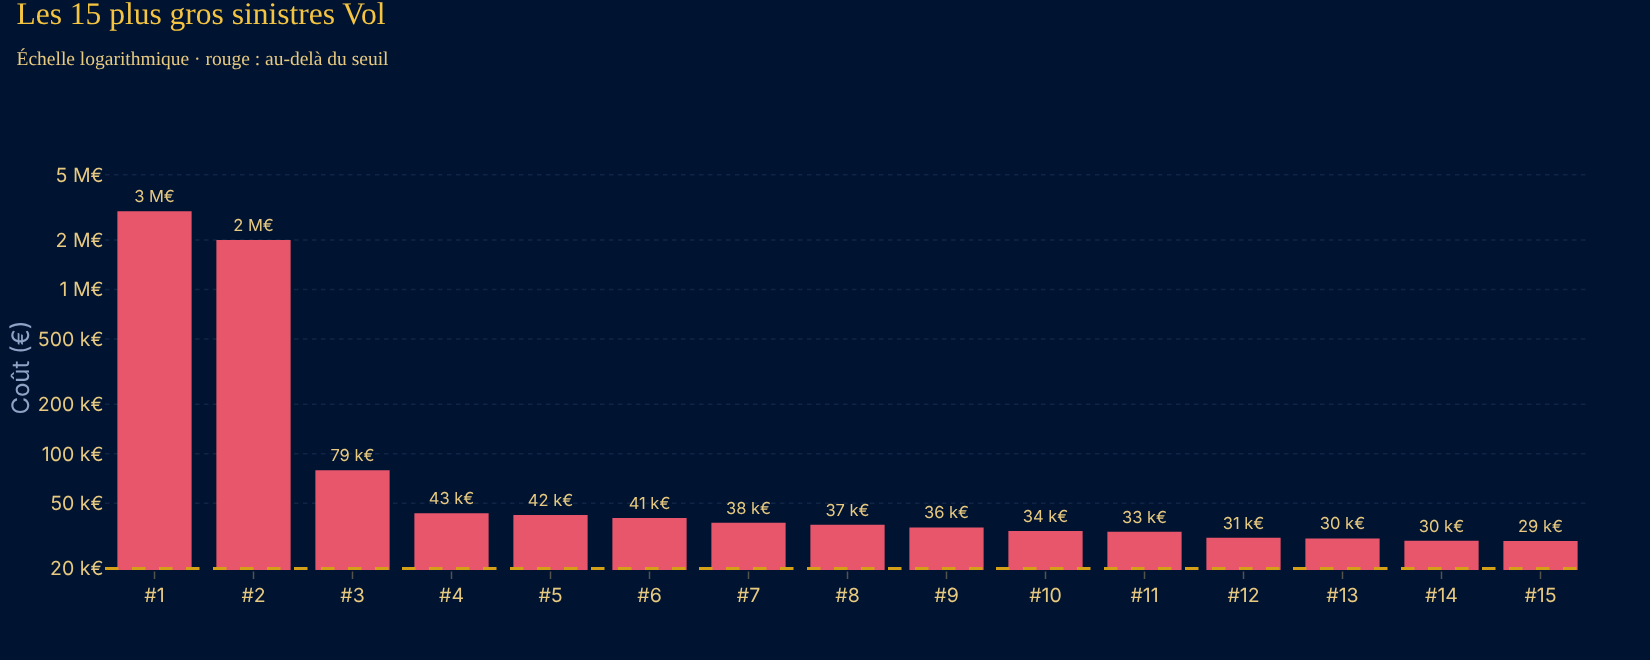

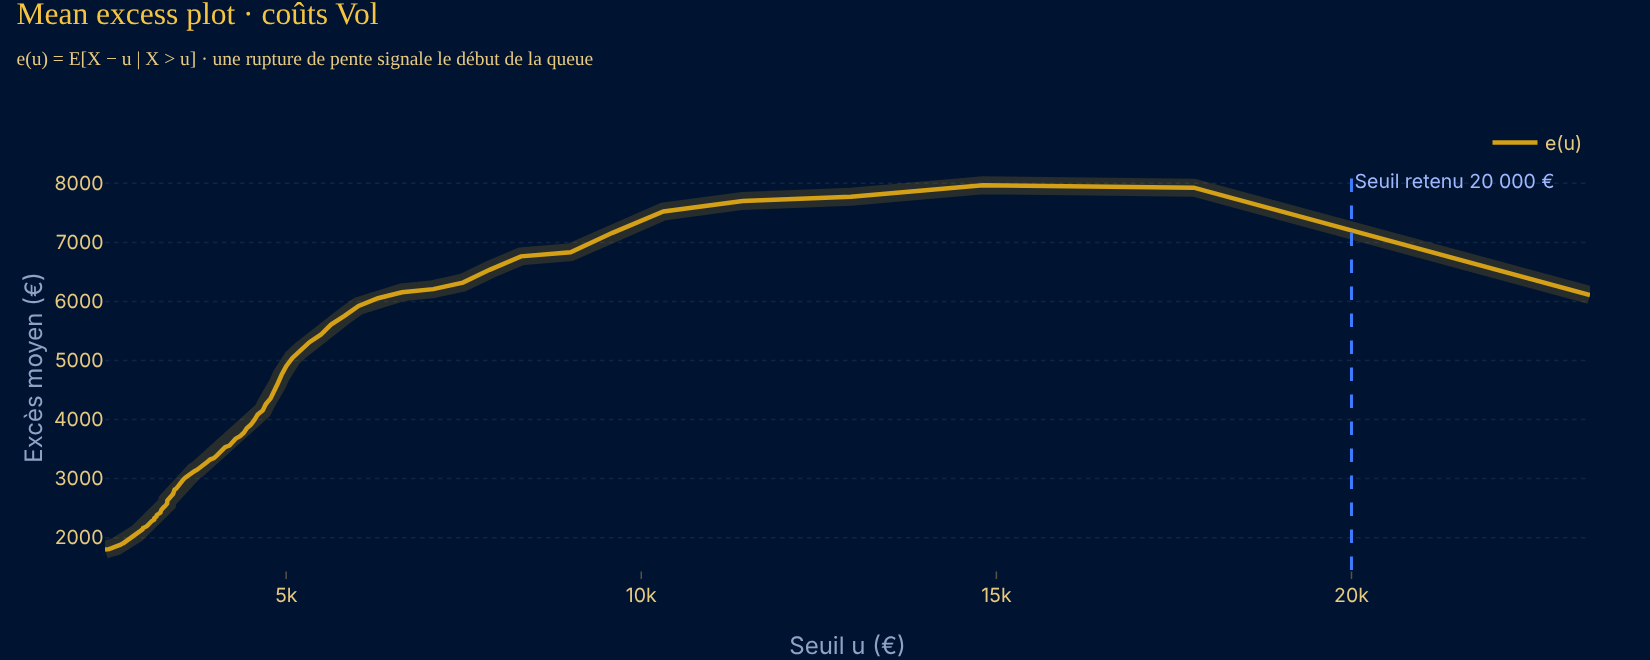

In [3]:
cu = couts_unitaires(bd2, "Vol")
print(cu.describe(percentiles=[.5, .99, .995, .999]).apply("{:,.0f}".format))
print(f"Part de la charge Vol portée par les 2 sinistres injectés : {5e6 / bd2['Cout_Vol'].sum():.1%}")
GR.top_sinistres(cu, 15, 20_000).show()
s, me = mean_excess(cu[cu < 1e6])
GR.mean_excess(s, me, 20_000).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Oui : les deux sinistres injectés valent 25 à 40 fois le plus gros sinistre naturel (≈ 79 000 €) et représentent
une part considérable de la charge Vol de huit exercices. **Il faut les retraiter** : un GLM Gamma estime une moyenne
par cellule, et un seul point extrême fait exploser le coût moyen de sa cellule. **Sans retraitement**, l'assureur
surtarife quelques profils au hasard de l'endroit où le grave est tombé (ils partiront à la concurrence) et
sous-tarifie les autres, la charge grave n'étant pas financée de manière cohérente ; la prime devient instable d'une
année sur l'autre.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Question 2 · Méthodologie : écrêtement + mutualisation</h3>

1. **Seuil** $u$ au début de la queue : rupture de pente du mean excess plot, ≈ quantile 99,5 %. On retient **20 000 €**.
2. **Écrêtement** : chaque sinistre est plafonné à $u$ ; le GLM Gamma est estimé sur le coût moyen écrêté.
3. **Mutualisation** : la charge au-delà de $u$ est répartie sur tous les assurés par un coefficient
   $1 + k$, avec $k = \dfrac{\sum (X-u)^+}{\sum \min(X,u)}$ estimé sur l'historique le plus long disponible.
4. Prime pure = fréquence × CM écrêté × (1 + k).

In [4]:
SEUIL = 20_000
display(synthese_seuils(bd2, [10_000, 15_000, 20_000, 30_000, 50_000]).style.format(
    {"Seuil": "{:,.0f} €", "Part écrêtée de la charge": "{:.2%}", "Taux de surcharge": "{:.2%}"}))
k = taux_surcharge(bd2, SEUIL, "Vol")
print(f"Taux de surcharge retenu (historique complet, graves inclus) : {k:.2%}")

,Seuil,Nb sinistres écrêtés,Part écrêtée de la charge,Taux de surcharge
0,"10,000 €",258,18.56%,22.79%
1,"15,000 €",127,15.99%,19.04%
2,"20,000 €",76,14.62%,17.13%
3,"30,000 €",13,13.42%,15.49%
4,"50,000 €",3,13.05%,15.01%


Taux de surcharge retenu (historique complet, graves inclus) : 17.13%


In [5]:
bdc_e = base_cout_ecretee(bda, SEUIL, "Vol")
fit_f = M.glm_freq(bda, VAR_TARIF_VOL, "Vol")                         # fréquence (inchangée par l'écrêtement)
fit_c_brut = M.glm_cout(bdc, VAR_TARIF_VOL, "Vol")                    # sans retraitement
fit_c_ecr = M.glm_cout(bdc_e, VAR_TARIF_VOL, "Vol", cible="CM_Vol_ecr")
propre = bdc[bdc["Cout_Vol"] < 1e6]
fit_c_ref = M.glm_cout(propre, VAR_TARIF_VOL, "Vol")                  # référence sans graves
comp = pd.DataFrame({"Sans graves": np.exp(fit_c_ref.params), "Non retraité": np.exp(fit_c_brut.params),
                     "Écrêté": np.exp(fit_c_ecr.params)})
display(comp.style.format("{:.3f}"))

,Sans graves,Non retraité,Écrêté
Intercept,2443.867,2443.867,2370.848
Couverture[T.C2],1.110,1.110,1.105
Couverture[T.C3],1.261,1.261,1.273
Qualite[T.Prop],1.243,1.243,1.240
Zonier_Vol[T.Z2],0.915,0.915,0.938
Zonier_Vol[T.Z3],0.899,0.899,0.927
Zonier_Vol[T.Z4],1.010,1.010,1.040
Zonier_Vol[T.Z5],0.778,0.778,0.793


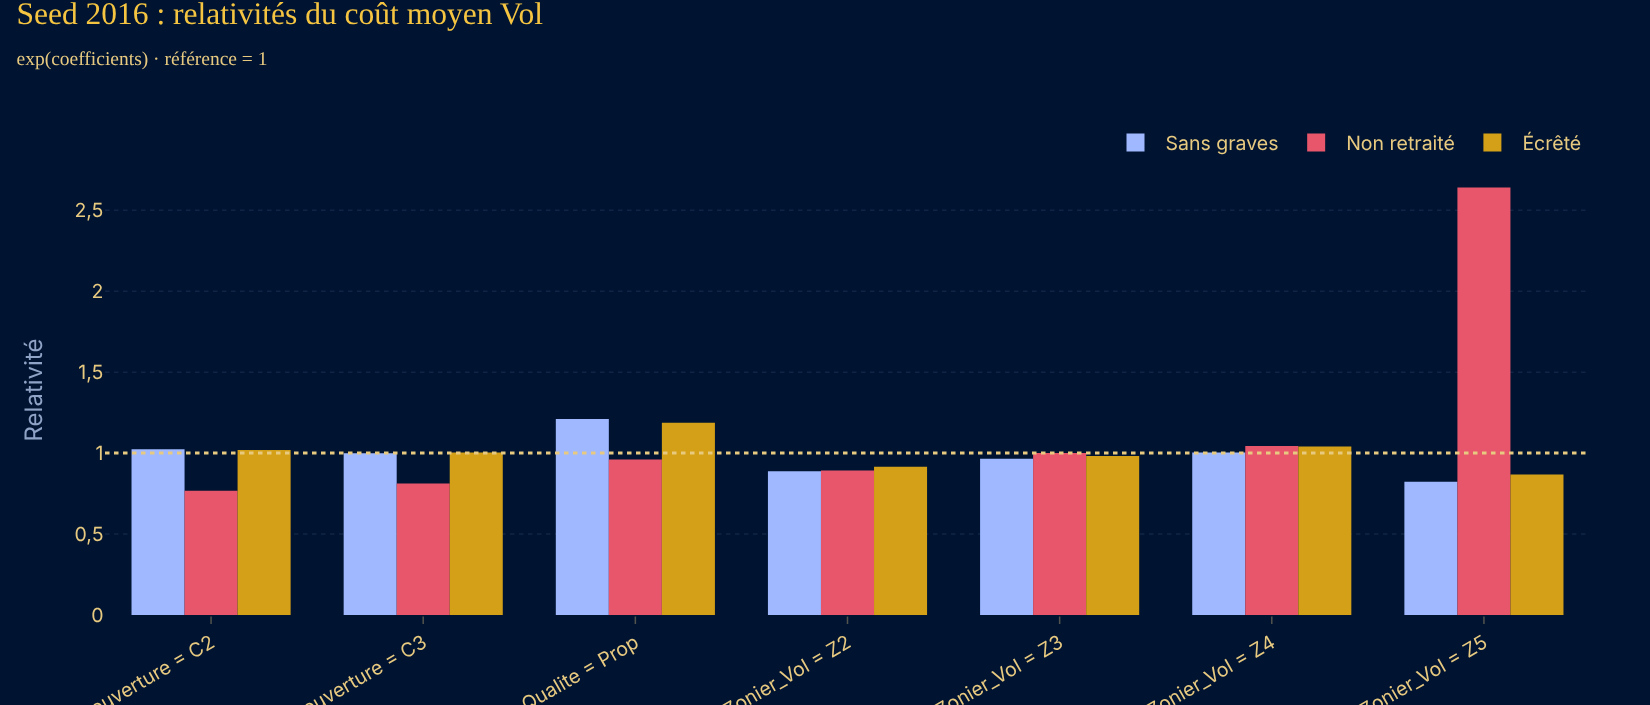

Intercept (CM de référence) : sans graves 2,608 € · non retraité 3,620 € · écrêté 2,554 €


In [6]:
# Même analyse avec le découpage du corrigé (seed 2016), où le grave de 2 M€ est en apprentissage
bda16, bdt16, _ = decouper(bd2, seed=2016)
bdc16 = base_cout(bda16, "Vol"); bdc16_e = base_cout_ecretee(bda16, SEUIL, "Vol")
c16_brut = M.glm_cout(bdc16, VAR_TARIF_VOL, "Vol"); c16_ecr = M.glm_cout(bdc16_e, VAR_TARIF_VOL, "Vol", cible="CM_Vol_ecr")
c16_ref = M.glm_cout(bdc16[bdc16["Cout_Vol"] < 1e6], VAR_TARIF_VOL, "Vol")
comp16 = pd.DataFrame({"Sans graves": np.exp(c16_ref.params), "Non retraité": np.exp(c16_brut.params),
                       "Écrêté": np.exp(c16_ecr.params)})
t = comp16.drop("Intercept").reset_index(names="Terme")
t["Terme"] = t["Terme"].str.replace("[T.", " = ", regex=False).str.replace("]", "", regex=False)
GR.comparaison_coefficients(t, "Seed 2016 : relativités du coût moyen Vol").show()
print(f"Intercept (CM de référence) : sans graves {comp16.loc['Intercept', 'Sans graves']:,.0f} € · "
      f"non retraité {comp16.loc['Intercept', 'Non retraité']:,.0f} € · écrêté {comp16.loc['Intercept', 'Écrêté']:,.0f} €")

#### Qualité des modèles et comportement en marché concurrentiel (seed 2021, base test)

In [7]:
from src.marche import simuler_marche
pp_brut = M.prime_pure(fit_f, fit_c_brut, bdt).to_numpy()
pp_ecr = (M.prime_pure(fit_f, fit_c_ecr, bdt) * (1 + k)).to_numpy()
obs = bdt["Cout_Vol"].sum()
print(f"Charge observée test : {obs:,.0f} € (dont 5 M€ de graves)")
print(f"Prédite non retraitée : {pp_brut.sum():,.0f} € · écrêtée + mutualisée : {pp_ecr.sum():,.0f} €")
for nom, d in [("16 brut", c16_brut), ("16 écrêté", c16_ecr)]:
    print(f"AIC coût seed 2016 {nom} : {d.aic:,.0f}")
sim = simuler_marche({"Non retraité": pp_brut, "Écrêté + mutualisé": pp_ecr}, {"Non retraité": .15, "Écrêté + mutualisé": .15},
                     bdt["Cout_Vol"].to_numpy())
display(sim["synthese"][["Assureur", "Part de marché", "Primes encaissées", "Sinistres payés", "Résultat", "S/P"]]
        .style.format({"Part de marché": "{:.1%}", "Primes encaissées": "{:,.0f} €", "Sinistres payés": "{:,.0f} €",
                       "Résultat": "{:,.0f} €", "S/P": "{:.1%}"}))

Charge observée test : 28,975,998 € (dont 5 M€ de graves)
Prédite non retraitée : 23,830,059 € · écrêtée + mutualisée : 27,558,602 €
AIC coût seed 2016 16 brut : 63,738
AIC coût seed 2016 16 écrêté : 54,347


,Assureur,Part de marché,Primes encaissées,Sinistres payés,Résultat,S/P
0,Non retraité,100.0%,"27,404,568 €","28,975,998 €","-1,571,431 €",105.7%
1,Écrêté + mutualisé,0.0%,0 €,0 €,0 €,nan%


,Assureur,Part de marché,Résultat,S/P
0,Non retraité,77.9%,"-481,888 €",102.2%
1,Écrêté + mutualisé,22.1%,"1,183,089 €",78.5%


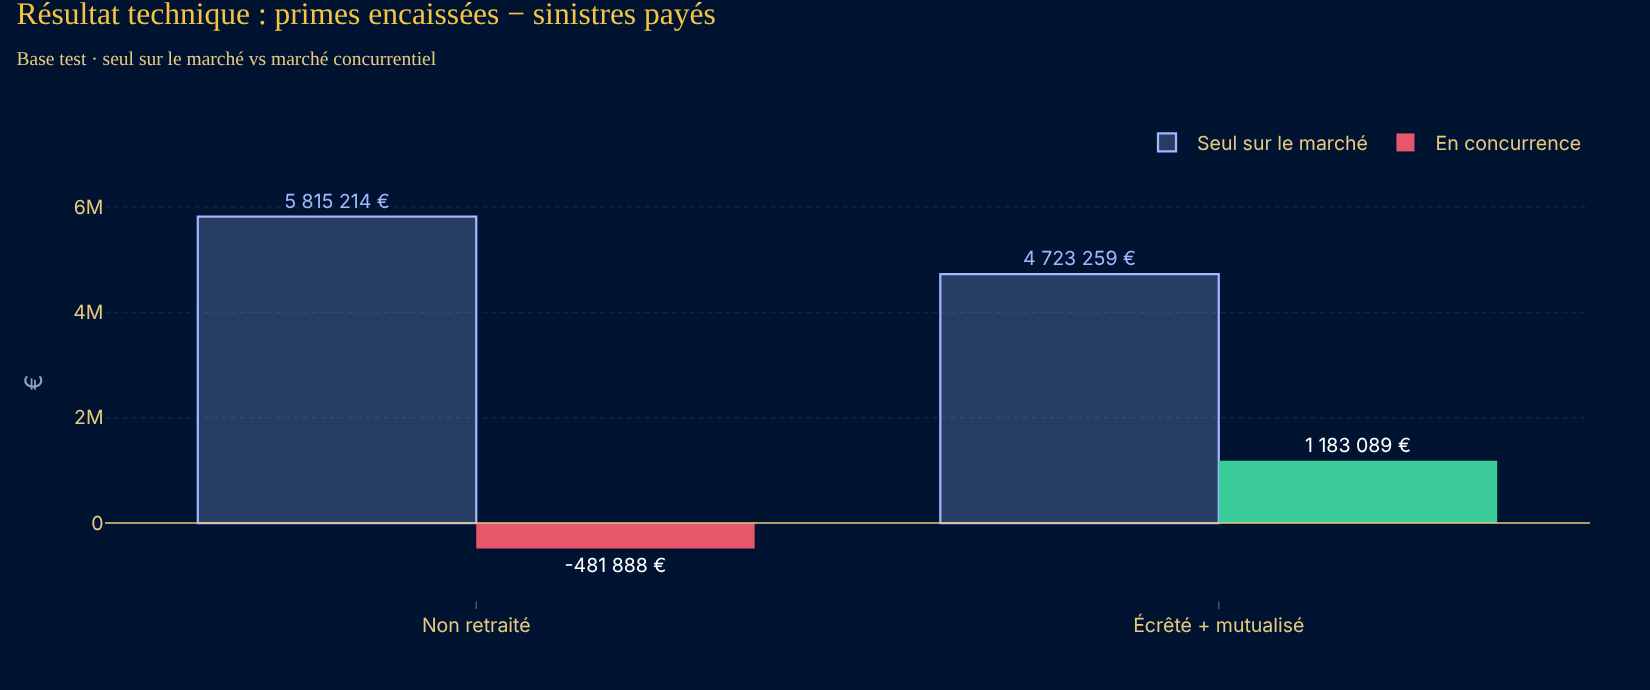

In [8]:
# Même duel avec le découpage seed 2016
f16 = M.glm_freq(bda16, VAR_TARIF_VOL, "Vol")
p16_b = M.prime_pure(f16, c16_brut, bdt16).to_numpy(); p16_e = (M.prime_pure(f16, c16_ecr, bdt16) * (1 + k)).to_numpy()
sim16 = simuler_marche({"Non retraité": p16_b, "Écrêté + mutualisé": p16_e}, {"Non retraité": .15, "Écrêté + mutualisé": .15},
                       bdt16["Cout_Vol"].to_numpy())
display(sim16["synthese"][["Assureur", "Part de marché", "Résultat", "S/P"]].style.format(
    {"Part de marché": "{:.1%}", "Résultat": "{:,.0f} €", "S/P": "{:.1%}"}))
GR.resultats_assureurs(sim16["synthese"].set_index("Assureur")["Résultat seul"].to_dict(),
                       sim16["synthese"].set_index("Assureur")["Résultat"].to_dict()).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> **Seed 2016** (grave de 2 M€ en apprentissage, dans la cellule de référence) : sans retraitement, le coût moyen de
référence passe de ≈ 2 600 € à ≈ 3 600 € et **toutes** les primes sont gonflées ; l'AIC du modèle de coût se dégrade
fortement (≈ 63 700 contre ≈ 54 300 écrêté). Le modèle écrêté retrouve les coefficients de la référence sans graves.
En concurrence, l'assureur non retraité est plus cher sur les profils proches de la référence et moins cher ailleurs :
il garde 78 % du marché mais perd ≈ 0,5 M€ (S/P 102 %), tandis que l'assureur qui écrête et mutualise gagne ≈ 1,2 M€
(S/P 79 %).
**Seed 2021** (graves en test) : l'échantillon d'apprentissage n'en contient aucun, les deux modèles de coût sont
presque identiques et seul l'assureur prudent ajoute la surcharge grave (≈ 17 %, estimée sur tout l'historique).
Il est donc plus cher partout et ne vend rien, mais l'assureur qui prend tout le marché perd ≈ 1,6 M€ (S/P 106 %)
quand les 5 M€ de graves surviennent : mieux vaut ne pas vendre que vendre à perte. La charge prédite écrêtée +
mutualisée (27,6 M€) est bien plus proche de la charge réelle (29,0 M€) que celle du modèle brut (23,8 M€).
**Conclusion** : on écrête au seuil de la queue, on modélise la sinistralité attritionnelle par GLM fréquence × coût,
et on finance les graves par une charge mutualisée estimée sur l'historique le plus long (complétée en pratique par
une réassurance en excédent de sinistre).</div>